# Lab 9 : Morphological Operations

### Student: Nawaf Rabea Shahbal - 2240009025

## Task 1: Apply Morphological Operations to a New Image
Select Balls.png and apply Erosion, Dilation, Opening, and Closing.

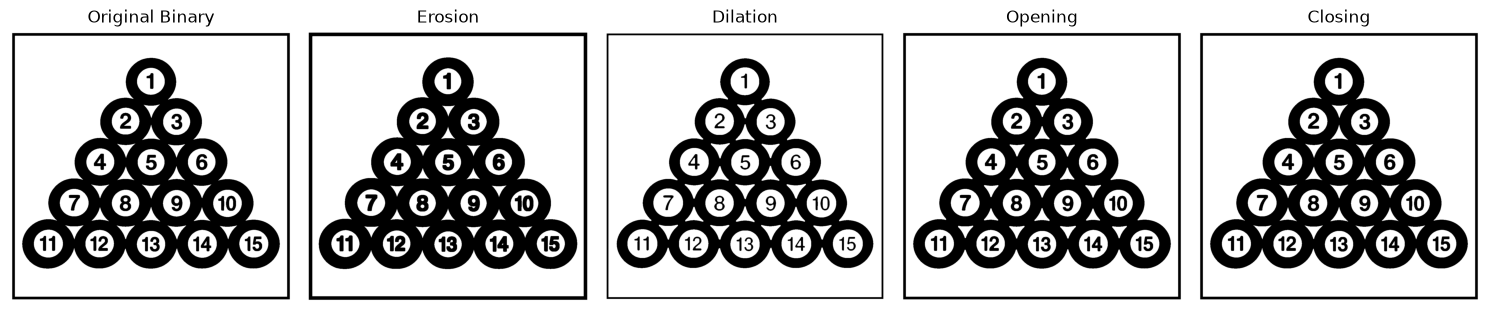

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Balls.png'

# 1. Load image in grayscale and binarize using Otsu thresholding
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define a 5x5 kernel
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Erosion, Dilation, Opening, and Closing
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 4. Display the original image and the results of each operation
titles = ['Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [binary, erosion, dilation, opening, closing]

plt.figure(figsize=(15, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

## Task 2: Experiment with Structuring Elements
Apply erosion and dilation using square, cross, and ellipse structuring elements with kernel sizes 3x3, 5x5, and 7x7.

### 1. Erosion with Different Shapes and Kernel Sizes

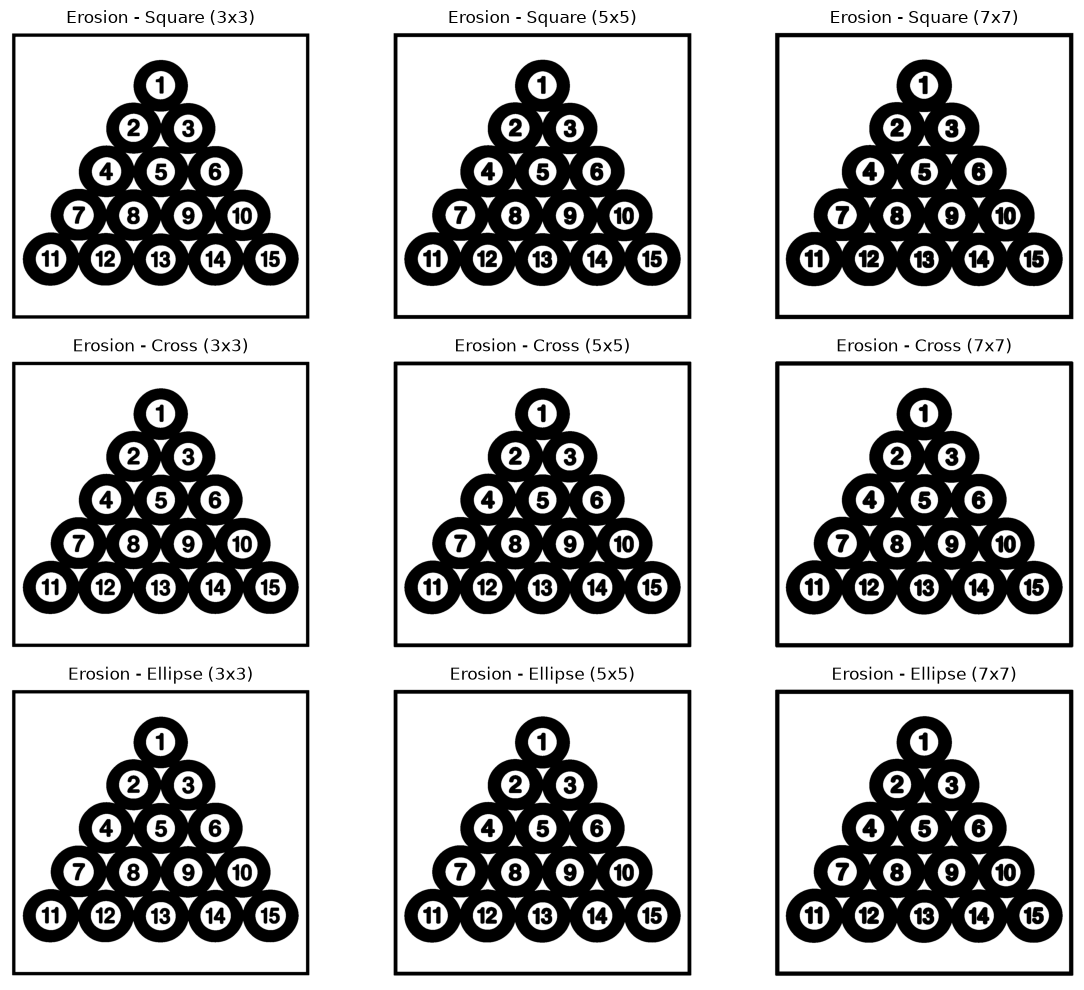

In [2]:
shapes = {
    'Square': cv2.MORPH_RECT,
    'Cross': cv2.MORPH_CROSS,
    'Ellipse': cv2.MORPH_ELLIPSE
}
sizes = [3, 5, 7]

plt.figure(figsize=(12, 10))
plot_idx = 1
for shape_name, shape_flag in shapes.items():
    for k in sizes:
        se = cv2.getStructuringElement(shape_flag, (k, k))
        eroded = cv2.erode(binary, se, iterations=1)
        plt.subplot(3, 3, plot_idx)
        plt.imshow(eroded, cmap='gray')
        plt.title(f'Erosion - {shape_name} ({k}x{k})')
        plt.axis('off')
        plot_idx += 1
plt.tight_layout()
plt.show()

### 2. Dilation with Different Shapes and Kernel Sizes

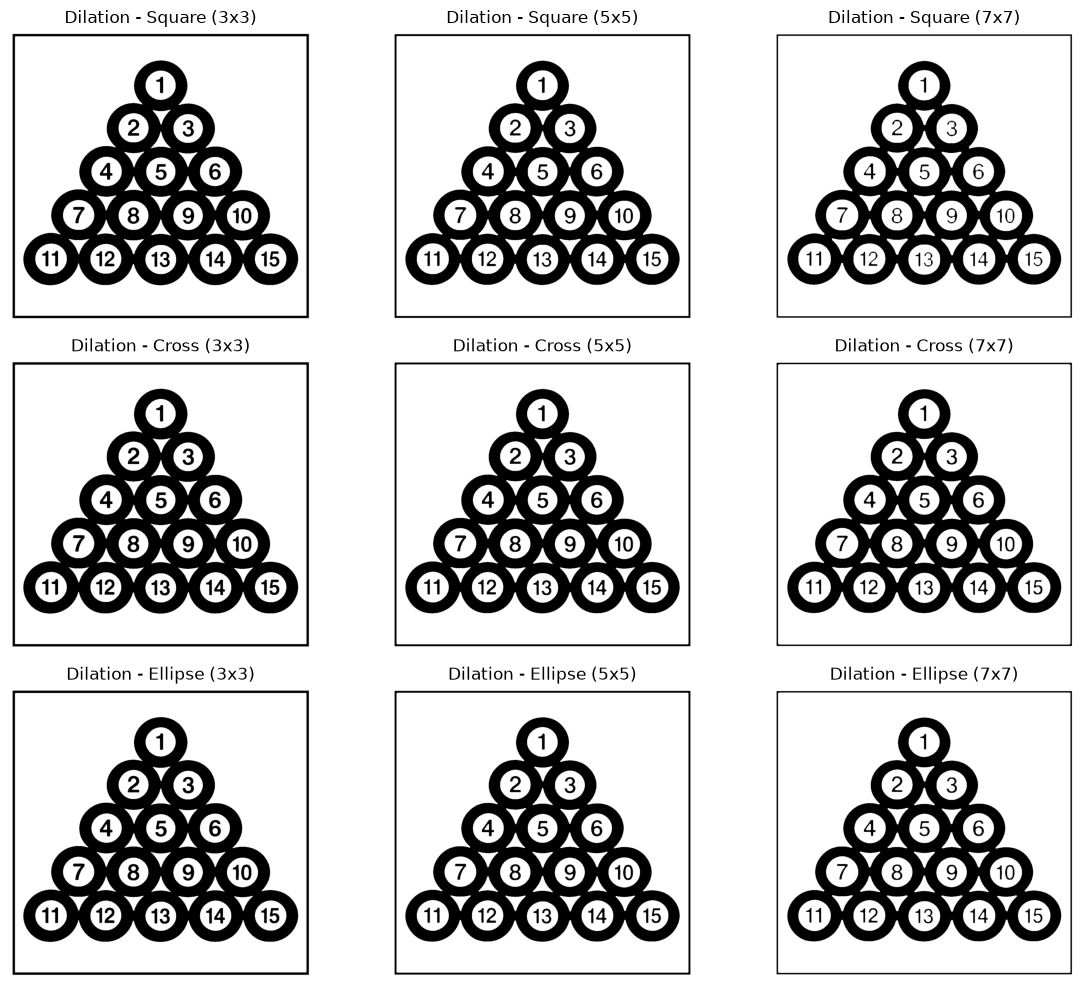

In [3]:
plt.figure(figsize=(12, 10))
plot_idx = 1
for shape_name, shape_flag in shapes.items():
    for k in sizes:
        se = cv2.getStructuringElement(shape_flag, (k, k))
        dilated = cv2.dilate(binary, se, iterations=1)
        plt.subplot(3, 3, plot_idx)
        plt.imshow(dilated, cmap='gray')
        plt.title(f'Dilation - {shape_name} ({k}x{k})')
        plt.axis('off')
        plot_idx += 1
plt.tight_layout()
plt.show()

### Comparison of Results
- Effect of Kernel Size (3x3, 5x5, 7x7): As the kernel size increases from 3x3 to 7x7, the morphological effect becomes stronger. In erosion, white regions shrink more and black regions (the balls and numbers) appear thicker. In dilation, white regions expand more and thin black lines (such as the numbers inside the balls) become thinner or start to disappear.
- Effect of Structuring Element Shape (Square, Cross, Ellipse): The square kernel affects corners and diagonals the most, producing sharper and more blocky changes. The cross kernel mainly affects horizontal and vertical neighbors, so it preserves diagonal details better and has a milder effect. The ellipse kernel gives smoother and more rounded boundaries, which fits circular objects like the balls well.